# Estimadores de CCF sobre un generador con verdad conocida: qué fecha de referencia sesga la EAD

**Pregunta:** Cuando el giro de las líneas rotativas se acelera antes del incumplimiento, ¿qué diseño de fecha de referencia y qué tratamiento de los valores extremos recuperan el factor de conversión conocido de una cartera generada, y qué tan grande es el sesgo de cada uno frente a una tolerancia de 0,02?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 y 02 de este tema (el factor, sus diseños y sus tratamientos)
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este notebook puedes:

- leer los seis niveles de aceleración del generador de C09 y decir cuál es su CCF conocido en cada uno;
- explicar las dos agregaciones de un conjunto de factores, la media y la razón agrupada, y por qué difieren cuando las líneas con más monto no utilizado giran menos;
- calcular el sesgo de un estimador contra la verdad conocida con `ccf_bias`, leer `ccf_estimator_bias` (estadístico, valor p, tolerancia y semáforo) y decir por qué un sesgo significativo dentro de la tolerancia queda en verde;
- correr los tres diseños de fecha de referencia y los tratamientos de un factor fuera de [0, 1] sobre diez replicaciones generadas en cada nivel, y decir cuánto del resultado es una propiedad del horizonte propio del generador;
- ajustar los dos modelos de EAD que no necesitan factor, `fit_direct_ead` y `fit_utilisation_change`, sobre líneas generadas y ver por qué el primero no puede predecir sobre el límite.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti.

In [1]:
# Poner el código del caso en la ruta de importación, importar los paquetes e imprimir sus versiones
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import ccf
from riskvalidation.validation import lgd_ead as lgd_tests

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.c09 import estimators, generator, params

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Siete artefactos versionados del caso C09, la exposición al incumplimiento de líneas de crédito rotativas: el artefacto del generador `models-generator.json` y las variantes `level-0.json` a `level-5.json`, una por nivel de aceleración. C09 tiene **una verdad conocida**: sus líneas las produce un generador cuyas distribuciones marginales siguen las carteras hipotéticas de tarjetas de la Reserva Federal de 2025, y cuyo factor de conversión es un parámetro propio. En el nivel 0 el monto no utilizado se gira a ritmo constante durante los doce meses previos al incumplimiento. Desde el nivel 1 el ritmo de giro se acelera en los últimos seis meses por un factor de 1,25 hasta 3, lo que sube el CCF conocido, porque el saldo crece más rápido cerca del incumplimiento. Los datos son sintéticos y no dicen nada sobre ningún prestamista.

Los artefactos guardan el plan de replicaciones (las semillas) y las estimaciones versionadas sobre veinte replicaciones de prueba de 50.000 facilidades. Este notebook no lee esas estimaciones para responder su pregunta: vuelve a sortear diez de las replicaciones de prueba con el generador propio del caso y las semillas del plan, estima cada diseño sobre ellas con el motor, y solo dibuja los sesgos versionados de las veinte replicaciones como una referencia discontinua en la figura del paso 3. No se escribe nada en disco.

In [2]:
# Cargar el artefacto del generador y los seis niveles; imprimir el plan y el CCF conocido de cada nivel
derived = ROOT / "data" / "derived" / "C09"
gen = json.loads((derived / "models-generator.json").read_text(encoding="utf-8"))["fit"]
levels = [json.loads((derived / f"level-{i}.json").read_text(encoding="utf-8")) for i in range(6)]
plan = gen["replications_plan"]
print("horneado con riskvalidation:", sorted({v["provenance"]["riskvalidation_version"] for v in levels}))
print("instalado:", rv.__version__)
n_dev, n_test = len(plan["development_seeds"]), len(plan["test_seeds"])
print(f"plan versionado: {n_dev} desarrollo + {n_test} prueba | {plan['n_facilities']:,} facilidades")
print(f"{'nivel':>6s} {'aceleración':>14s} {'CCF conocido':>16s}")
for lv in gen["levels"]:
    print(f"{lv['level']:6d} {lv['acceleration_factor']:14.2f} {params.known_ccf(lv['level'], 12):16.6f}")

horneado con riskvalidation: ['1.0.1']
instalado: 1.0.1
plan versionado: 20 desarrollo + 20 prueba | 50,000 facilidades
 nivel    aceleración     CCF conocido
     0           1.00         0.600000
     1           1.25         0.634252
     2           1.50         0.664272
     3           2.00         0.714173
     4           2.50         0.753697
     5           3.00         0.785540


## Método

### Paso 1: dos formas de combinar los factores

Dados los factores $c_i$ de $N$ incumplidores y sus montos no utilizados $U_i = L_i - E_i$ en la fecha de referencia, `aggregate_ccf(ccf, undrawn, aggregator)` del motor ofrece dos resúmenes:

$$\text{media} = \frac{1}{N}\sum_i c_i, \qquad \text{agrupado} = \frac{\sum_i c_i\,U_i}{\sum_i U_i} = \frac{\sum_i (EAD_i - E_i)}{\sum_i (L_i - E_i)}$$

(Fuente: el docstring de `aggregate_ccf`; los factores no definidos se excluyen y un conjunto sin ningún factor definido produce un error.) La media da a cada incumplidor el mismo peso; la razón agrupada da el mismo peso a cada unidad de monto no utilizado, así que es la parte de la *moneda* no utilizada que se usó. Las dos difieren cuando el factor depende del tamaño del monto no utilizado. La celda inventa seis incumplidores, tres con poco monto no utilizado que lo usan todo y tres con mucho que usan poco, e imprime ambas.

In [3]:
# Seis incumplidores inventados, montos pequeños girados por completo y grandes girados poco: media y agrupada
factor = np.array([1.0, 1.0, 1.0, 0.2, 0.2, 0.2])
undrawn = np.array([10.0, 10.0, 10.0, 1_000.0, 1_000.0, 1_000.0])
mean_c = ccf.aggregate_ccf(factor, undrawn, "mean")
pooled_c = ccf.aggregate_ccf(factor, undrawn, "pooled")
print(f"media = {mean_c:.4f} | agrupada = {pooled_c:.4f}")
weighted, total = np.sum(factor * undrawn), np.sum(undrawn)
print(f"agrupada a mano: sum(c * U) / sum(U) = {weighted:.1f} / {total:.1f} = {weighted / total:.4f}")

media = 0.6000 | agrupada = 0.2079
agrupada a mano: sum(c * U) / sum(U) = 630.0 / 3030.0 = 0.2079


### Paso 2: el sesgo de un estimador y su prueba

Un generador conoce el CCF verdadero, así que un estimador se puede puntuar: `ccf_bias(estimate, truth)` es $\text{estimación} - \text{verdad}$, con signo y sin recorte. C09 repite el experimento $R = 20$ veces y `ccf_estimator_bias(estimates, truth, tolerance)` del motor resume las réplicas. Con $e_r = \hat c_r - c$ el error de la réplica $r$:

$$\text{sesgo} = \bar e, \qquad \text{RMSE} = \sqrt{\overline{e^2}}, \qquad t = \frac{\bar e}{s_e/\sqrt{R}} \; (R - 1 \text{ grados de libertad}), \qquad p = 2\,P(T_{R-1} > |t|)$$

La luz depende solo del sesgo y de una tolerancia, no del valor p: verde cuando $|\text{sesgo}| \le$ tolerancia, ámbar hasta el doble, rojo sobre eso; el valor p es informativo, así que un sesgo estadísticamente significativo dentro de la tolerancia sigue en verde y la vista muestra ambos (todo del docstring de la función, un umbral interno de Contraste y no uno regulatorio). La tolerancia de C09 es 0.02.

La celda siguiente inventa las 20 estimaciones de dos estimadores contra una verdad de 0.6: uno con un sesgo pequeño y estable de -0.015, que es significativo y está dentro de la tolerancia, y uno con un sesgo de -0.05. Esos 40 números son inventados para mostrar cómo se lee la prueba.

In [4]:
# Evaluar dos estimadores inventados contra una verdad conocida de 0,6 con tolerancia de 0,02
light = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluado"}
rng = np.random.default_rng(11)
truth = 0.6
steady = truth - 0.015 + rng.normal(0.0, 0.004, 20)
poor = truth - 0.05 + rng.normal(0.0, 0.02, 20)
for label, est in (("estable, sesgo -0.015", steady), ("pobre, sesgo -0.05", poor)):
    res = lgd_tests.ccf_estimator_bias(est, truth, tolerance=0.02, model_id=label)
    direct_bias = ccf.ccf_bias(est.mean(), truth)
    print(f"{label:28s} sesgo {res.metric:8.4f} (ccf_bias {direct_bias:8.4f}) t={res.statistic:8.3f}")
    inside = res.extras["within_tolerance"]
    rmse = res.extras["rmse"]
    print(f"{'':28s} p={res.p_value:.2e} RMSE={rmse:.4f} en tolerancia={inside} {light[res.light.value]}")

estable, sesgo -0.015        sesgo  -0.0142 (ccf_bias  -0.0142) t= -19.980
                             p=3.24e-14 RMSE=0.0145 en tolerancia=True verde
pobre, sesgo -0.05           sesgo  -0.0572 (ccf_bias  -0.0572) t= -15.166
                             p=4.54e-12 RMSE=0.0595 en tolerancia=False rojo


### Paso 3: correr el generador y estimar cada diseño

Ahora el experimento real, lo bastante pequeño para correr en el notebook. Para cada una de diez semillas de prueba del plan versionado la celda sortea la población de 50.000 facilidades, la realiza en cada uno de los seis niveles de aceleración, lee los factores de cada incumplidor bajo los tres diseños (`reference_indices` y `ccf_observations` a través del `observe` del caso) y los resume con `aggregate_ccf` como razón agrupada y como media. El CCF verdadero de cada nivel es la forma cerrada del generador, `params.known_ccf(level, 12)`, y el sesgo de una estimación es `ccf_bias(estimate, truth)`. La celda guarda las observaciones del nivel 3 del diseño de horizonte fijo para el paso 5 e imprime el sesgo medio sobre las diez replicaciones.

In [5]:
# Sortear diez replicaciones, estimar los tres diseños en seis niveles e imprimir el sesgo agrupado medio
DESIGNS = ("fixed-horizon", "cohort", "variable-horizon")
shown = {"fixed-horizon": "fijo", "cohort": "cohorte", "variable-horizon": "variable"}
estimates = {(lv, d, a): [] for lv in range(6) for d in DESIGNS for a in ("mean", "pooled")}
level3 = []
for seed in plan["test_seeds"][:10]:
    population = generator.draw_population(seed, 50_000)
    for lv in range(6):
        lines = generator.realise(population, lv)
        for d in DESIGNS:
            obs = estimators.observe(lines, d)
            for a in ("mean", "pooled"):
                estimates[(lv, d, a)].append(ccf.aggregate_ccf(obs.ccf, obs.undrawn, a))
            if lv == 3 and d == "fixed-horizon":
                level3.append(obs)
truth = [params.known_ccf(lv, 12) for lv in range(6)]
bias = {k: np.mean([ccf.ccf_bias(e, truth[k[0]]) for e in v]) for k, v in estimates.items()}
print(f"{'nivel':>6s} {'CCF conocido':>12s} " + " ".join(f"{shown[d]:>9s}" for d in DESIGNS))
for lv in range(6):
    print(f"{lv:6d} {truth[lv]:12.4f} " + " ".join(f"{bias[(lv, d, 'pooled')]:9.4f}" for d in DESIGNS))
mean_bias = ", ".join(f"{bias[(lv, 'fixed-horizon', 'mean')]:.4f}" for lv in range(6))
print("sesgo de la media de los factores, horizonte fijo, niveles 0 a 5:", mean_bias)

 nivel CCF conocido      fijo   cohorte  variable
     0       0.6000   -0.0228   -0.2615   -0.1835
     1       0.6343   -0.0228   -0.2525   -0.1752
     2       0.6643   -0.0226   -0.2437   -0.1673
     3       0.7142   -0.0218   -0.2270   -0.1530
     4       0.7537   -0.0209   -0.2121   -0.1405
     5       0.7855   -0.0198   -0.1988   -0.1298
sesgo de la media de los factores, horizonte fijo, niveles 0 a 5: -0.0005, -0.0004, -0.0004, -0.0002, -0.0001, -0.0000


La figura dibuja el sesgo de la razón agrupada de cada diseño contra el nivel de aceleración, con la banda de tolerancia de más y menos 0,02 y, como líneas discontinuas, los sesgos que los artefactos versionaron sobre veinte replicaciones. La razón agrupada es la agregación que conviene leer para los diseños de cohorte y de horizonte variable: el sesgo de su media simple es errático y su variación muestral es amplia, porque una razón con un monto no utilizado pequeño en el denominador no está acotada y unas pocas de esas líneas dominan una media sin ponderar.

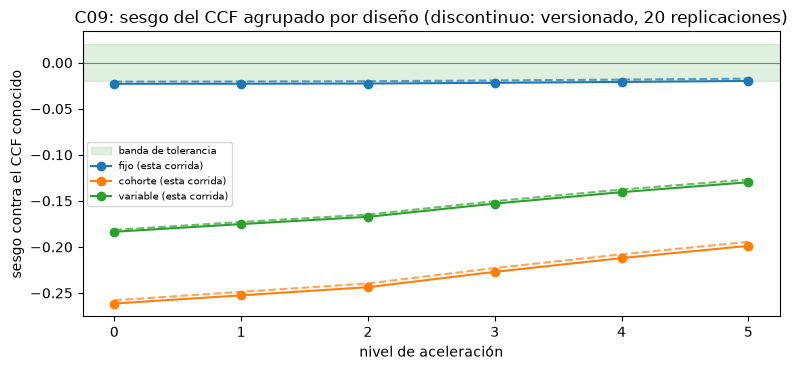

In [6]:
# Dibujar el sesgo agrupado de los tres diseños contra el nivel, con la banda de tolerancia y los versionados
tolerance = levels[0]["outputs"]["ccf_by_design"]["tolerance"]
tables = [doc["outputs"]["ccf_by_design"]["rows"] for doc in levels]
rows = [{(r["design"], r["treatment"], r["estimator"]): r for r in table} for table in tables]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.axhspan(-tolerance, tolerance, color="tab:green", alpha=0.15, label="banda de tolerancia")
for k, design in enumerate(DESIGNS):
    mine = [bias[(lv, design, "pooled")] for lv in range(6)]
    ax.plot(range(6), mine, marker="o", color=f"C{k}", label=f"{shown[design]} (esta corrida)")
    committed = [row[(design, "none", "pooled")]["bias"] for row in rows]
    ax.plot(range(6), committed, linestyle="--", color=f"C{k}", alpha=0.7)
ax.axhline(0.0, color="grey", linewidth=0.8)
ax.set_xlabel("nivel de aceleración")
ax.set_ylabel("sesgo contra el CCF conocido")
ax.set_title("C09: sesgo del CCF agrupado por diseño (discontinuo: versionado, 20 replicaciones)")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

La figura se lee en dos pasos. El diseño de horizonte fijo queda en el borde inferior de la banda verde en todos los niveles, a unos 0,003 de la línea discontinua versionada: diez replicaciones caen donde cayeron veinte. Una cautela antes de leerla como un ranking: el generador define su CCF conocido sobre los doce meses previos al incumplimiento, que es exactamente el horizonte del diseño `fixed-horizon`. Ese diseño mide entonces la cantidad para la que está definida la verdad, y su sesgo pequeño lo es en parte por construcción. Los diseños de cohorte y de horizonte variable ponen la fecha de referencia más tarde y miden la parte de un monto no utilizado menor, de modo que contra esta verdad leen bajo, en una magnitud que se estrecha a medida que crece la aceleración. Lo que muestra la figura es cuán grande es la brecha entre diseños sobre los mismos incumplimientos, no que un diseño sea correcto en general.

### Paso 4: la prueba de sesgo y su semáforo, sobre las replicaciones

`ccf_estimator_bias(estimates, truth, tolerance)` del motor resume las replicaciones de un estimador: el sesgo, el RMSE, un estadístico t y un valor p, y un semáforo fijado solo por el sesgo contra la tolerancia. La celda lo aplica en el nivel 3 a los tres diseños, con la razón agrupada calculada en el paso 3, y a la media de los factores del diseño de horizonte fijo. El valor p es informativo: un sesgo estadísticamente significativo dentro de la tolerancia queda en verde.

In [7]:
# Correr ccf_estimator_bias sobre las diez replicaciones del nivel 3 para cuatro estimadores
cases = [(d, "pooled") for d in DESIGNS] + [("fixed-horizon", "mean")]
print(f"CCF conocido del nivel 3: {truth[3]:.4f} | tolerancia {tolerance}")
for d, a in cases:
    reps = np.array(estimates[(3, d, a)])
    res = lgd_tests.ccf_estimator_bias(reps, truth[3], tolerance=tolerance, model_id=f"{d}-{a}")
    head = f"{shown[d]:9s} {a:7s} sesgo {res.metric:8.4f}  t={res.statistic:8.2f}"
    print(head, f" p={res.p_value:.2e}  RMSE={res.extras['rmse']:.4f}  {light[res.light.value]}")

CCF conocido del nivel 3: 0.7142 | tolerancia 0.02
fijo      pooled  sesgo  -0.0218  t=   -4.72  p=1.09e-03  RMSE=0.0259  ámbar
cohorte   pooled  sesgo  -0.2270  t=  -53.23  p=1.47e-12  RMSE=0.2274  rojo
variable  pooled  sesgo  -0.1530  t=  -30.74  p=2.00e-10  RMSE=0.1537  rojo
fijo      mean    sesgo  -0.0002  t=   -0.08  p=9.34e-01  RMSE=0.0089  verde


### Paso 5: los tratamientos de un factor fuera de [0, 1]

El notebook 02 presentó los tratamientos de `treat_ccf`. Aquí está lo que hace cada uno al sesgo en el nivel 3, con el diseño de horizonte fijo y ambas agregaciones, sobre las diez replicaciones guardadas en el paso 3. `censor` descarta las observaciones fuera de [0, 1], lo que quita las líneas que giraron más que su monto no utilizado y así empuja la estimación hacia abajo; `floor-cap` las recorta, lo que el motor documenta como un sesgo de la EAD. La celda aplica cada tratamiento a cada replicación, agrega con el motor e informa el sesgo medio, y la figura lo dibuja contra la banda de tolerancia.

In [8]:
# Aplicar tres tratamientos a las observaciones de horizonte fijo del nivel 3 y agregar con ambos estimadores
treatments = ("none", "censor", "floor-cap")
by_treatment = {(t, a): [] for t in treatments for a in ("mean", "pooled")}
dropped = {t: [] for t in treatments}
for obs in level3:
    for t in treatments:
        kept = estimators.treat(obs, t)
        dropped[t].append(kept.n_dropped)
        for a in ("mean", "pooled"):
            by_treatment[(t, a)].append(ccf.aggregate_ccf(kept.values, kept.undrawn, a))
tbias = {k: np.mean([ccf.ccf_bias(e, truth[3]) for e in v]) for k, v in by_treatment.items()}
print(f"{'tratamiento':12s} {'descartados':>12s} {'media':>10s} {'agrupada':>10s}")
for t in treatments:
    print(f"{t:12s} {np.mean(dropped[t]):12.0f} {tbias[(t, 'mean')]:10.4f} {tbias[(t, 'pooled')]:10.4f}")
print(f"proporción de factores bajo 0: {estimators.treat(level3[0], 'none').n_below_zero / level3[0].ccf.size:.4f}")

tratamiento   descartados      media   agrupada
none                  432    -0.0002    -0.0218
censor                657    -0.0547    -0.0701
floor-cap             432    -0.0132    -0.0329
proporción de factores bajo 0: 0.0079


La tabla da el sesgo medio de cada tratamiento sobre las diez replicaciones, con el número de observaciones que descarta cada uno. La figura pone los mismos números contra la banda de tolerancia, para la media de los factores y para la razón agrupada lado a lado.

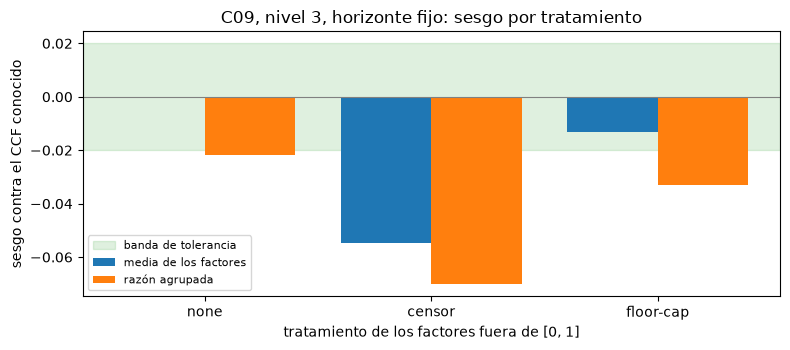

In [9]:
# Dibujar el sesgo de cada tratamiento contra la banda de tolerancia
fig, ax = plt.subplots(figsize=(8, 3.6))
positions = np.arange(len(treatments))
ax.axhspan(-tolerance, tolerance, color="tab:green", alpha=0.15, label="banda de tolerancia")
as_mean = [tbias[(t, "mean")] for t in treatments]
as_pooled = [tbias[(t, "pooled")] for t in treatments]
ax.bar(positions - 0.2, as_mean, width=0.4, color="tab:blue", label="media de los factores")
ax.bar(positions + 0.2, as_pooled, width=0.4, color="tab:orange", label="razón agrupada")
ax.axhline(0.0, color="grey", linewidth=0.8)
ax.set_xticks(positions)
ax.set_xticklabels(treatments)
ax.set_xlabel("tratamiento de los factores fuera de [0, 1]")
ax.set_ylabel("sesgo contra el CCF conocido")
ax.set_title("C09, nivel 3, horizonte fijo: sesgo por tratamiento")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Dejar los factores como están mantiene la media de los factores sobre la verdad y la razón agrupada justo fuera de la banda. Censurar es la elección dañina: quita las líneas que giraron todo su monto no utilizado y más, unas 225 observaciones más por replicación que las indefinidas, y ambas agregaciones caen muy fuera de la tolerancia. Recortar a [0, 1] mantiene la media dentro de la banda pero empuja la razón agrupada más abajo de la verdad que dejar los factores solos, porque los montos sobre el límite se cortan en 1. Un tratamiento que parece higiénico, descartar los valores incómodos, es entonces el que más sesga la estimación, y el sesgo lo informa la prueba del paso 4 en vez de ocultarse.

### Paso 6: modelos de EAD sin factor

La investigación pregunta si un modelo de la EAD misma, sin factor, lo hace mejor que el factor (Tong y otros 2016, como lo nombra el docstring del motor). El motor ajusta dos:

- `fit_direct_ead(X, ead, limit)`: un logit fraccional de $EAD / L$ sobre las covariables. Una EAD sobre el límite da una razón sobre 1; se recorta a 1 para el ajuste y se **cuenta** en `extras`, nunca en silencio. El motor señala que la mezcla gamma con ceros de Tong y otros (2016) no está en esta versión.
- `fit_utilisation_change(X, drawn_ref, drawn_default, limit_ref)`: mínimos cuadrados sobre el cambio de utilización $(E(t_d) - E(t_r)) / L(t_r)$, que no tiene monto no utilizado en el denominador.

`predict_ead` devuelve para el primero $L$ por la razón ajustada, dentro de $[0, L]$, y para el segundo $E(t_r) + L\,\hat\Delta$, sin recortar. La celda ajusta ambos sobre tres replicaciones de desarrollo del nivel 3 y predice las diez replicaciones de prueba guardadas en el paso 3, con las covariables que usa el caso (utilización, el logaritmo del límite y el puntaje crediticio).

In [10]:
# Ajustar los dos modelos de EAD sin factor sobre replicaciones de desarrollo del nivel 3 y predecir las de prueba
dev = [generator.generate(seed, 3, 50_000) for seed in plan["development_seeds"][:3]]
train = estimators.join([estimators.observe(d, "fixed-horizon") for d in dev])
test = estimators.join(level3)
cols = estimators.FEATURE_NAMES
direct = ccf.fit_direct_ead(estimators.features(train), train.ead, train.limit_ref, cols)
change = ccf.fit_utilisation_change(estimators.features(train), train.drawn_ref, train.ead, train.limit_ref, cols)
X_test = estimators.features(test)
pred_direct = ccf.predict_ead(direct, X_test, test.drawn_ref, test.limit_ref)
pred_change = ccf.predict_ead(change, X_test, test.drawn_ref, test.limit_ref)
print(f"observaciones de entrenamiento: {train.ead.size:,} | observaciones de prueba: {test.ead.size:,}")
print(f"EAD realizada media: {test.ead.mean():,.1f}")
print(f"EAD predicha media, directo: {pred_direct.mean():,.1f}")
print(f"EAD predicha media, cambio de utilización: {pred_change.mean():,.1f}")
over = test.limit_ref
print(f"EAD de prueba sobre el límite: {int((test.ead > over).sum())}")
print(f"predicciones sobre el límite, directo: {int((pred_direct > over).sum())}")
print(f"predicciones sobre el límite, cambio de utilización: {int((pred_change > over).sum())}")
print(f"líneas recortadas sobre el límite en el ajuste directo: {direct.extras['n_clipped_above']}")

observaciones de entrenamiento: 5,893 | observaciones de prueba: 19,342
EAD realizada media: 5,248.5
EAD predicha media, directo: 4,372.5
EAD predicha media, cambio de utilización: 5,296.2
EAD de prueba sobre el límite: 6430
predicciones sobre el límite, directo: 0
predicciones sobre el límite, cambio de utilización: 7723
líneas recortadas sobre el límite en el ajuste directo: 2052


## Resultados

**Respuesta:** Sobre diez replicaciones generadas, el diseño fijo de doce meses es el que mejor recupera el CCF conocido: en el nivel 3, donde la verdad es 0,7142, la media de sus factores la yerra por solo -0,0002 y su razón agrupada por -0,0218, en el borde de la tolerancia de 0,02, mientras los diseños de cohorte y de horizonte variable leen bajo por -0,2270 y -0,1530 y quedan en rojo. El tratamiento de los valores extremos importa tanto: censurar los factores fuera de [0, 1] lleva el sesgo agrupado a -0,0701 y recortarlos a -0,0329, frente a -0,0218 si se dejan.

- **La verdad se mueve con la aceleración.** El CCF conocido es 0,6000 en el nivel 0 y sube a 0,7855 en el nivel 5, a medida que el ritmo de giro de los últimos seis meses pasa de 1 a 3 veces su ritmo anterior.
- **La media y la razón agrupada son resúmenes distintos.** En los seis incumplidores inventados la media es 0,6000 y la razón agrupada 0,2079 (630,0 sobre 3.030,0), porque las tres líneas con un monto no utilizado grande giran poco.
- **La prueba lee el sesgo, y el semáforo lee la tolerancia.** En los estimadores inventados, el estable tiene un sesgo de -0,0142, un estadístico t de -19,980 y un valor p de 3,24e-14, y queda en verde porque está dentro de la tolerancia de 0,02; el pobre, con -0,0572, queda en rojo.
- **El diseño fijo de doce meses es casi insesgado, y eso es en parte por construcción.** El sesgo de su media de factores va de -0,0005 a -0,0000 en los seis niveles, y el de su razón agrupada de -0,0228 a -0,0198, en el borde de la tolerancia. El generador define su CCF sobre los mismos doce meses.
- **Las fechas de referencia más tardías leen bajo.** El sesgo agrupado del diseño de cohorte es -0,2615 en el nivel 0 y -0,1988 en el nivel 5, y el del diseño de horizonte variable -0,1835 y -0,1298: una fecha de referencia más cercana al incumplimiento mide la parte de un monto no utilizado menor, y la brecha se estrecha a medida que crece la aceleración.
- **Los tratamientos importan.** En el nivel 3, censurar lleva el sesgo de horizonte fijo a -0,0547 (media) y -0,0701 (agrupado) y descarta 657 observaciones por replicación frente a las 432 con factor indefinido; recortar da -0,0132 y -0,0329. Alrededor de 0,0079 de los factores de la primera replicación están bajo 0.
- **La prueba de sesgo coincide.** En el nivel 3 la razón agrupada de horizonte fijo queda en ámbar (sesgo -0,0218, t = -4,72, p = 1,09e-03, RMSE 0,0259); las razones agrupadas de cohorte (t = -53,23) y de horizonte variable (t = -30,74) quedan en rojo; la media de los factores de horizonte fijo queda en verde (t = -0,08, p = 9,34e-01).
- **Un modelo directo de EAD cuenta lo que recorta y no puede superar el límite.** Sobre 5.893 líneas de entrenamiento el ajuste directo recortó 2.052 sobre el límite; ninguna de sus predicciones de prueba queda sobre el límite aunque 6.430 de las 19.342 EAD de prueba lo están, y su predicción media es 4.372,5 frente a una media realizada de 5.248,5. El modelo de cambio de utilización, sin recorte, promedia 5.296,2 y predice sobre el límite en 7.723 líneas.

Lo que el notebook no hace: no dice qué diseño es el correcto para un banco, pues la verdad aquí está definida a doce meses y los datos son sintéticos. Diez replicaciones son un experimento menor que las veinte de los artefactos, y las líneas discontinuas de la figura muestran cuán cerca llegan. El notebook siguiente contrasta retrospectivamente los modelos de EAD por tramo de utilización.

## Resumen

- Un generador con CCF conocido convierte «¿qué diseño es el correcto?» en una medición: el sesgo de cada estimador contra la verdad, sobre replicaciones independientes, con una tolerancia.
- La media y la razón agrupada son resúmenes distintos y dan respuestas distintas cuando las líneas con más monto no utilizado giran menos; la razón agrupada es la parte de la moneda no utilizada que se giró.
- La fecha de referencia es un diseño con un costo: las fechas más tardías leen más bajo contra una verdad definida a doce meses, en una magnitud que se achica cuando sube la aceleración. El diseño fijo de doce meses es casi insesgado en parte porque coincide con el horizonte del generador.
- Tratar los factores fuera de [0, 1] mueve la estimación; censurar la sesga más y recortar menos, y la prueba informa el sesgo en vez de ocultarlo.
- Un modelo directo de EAD cuenta las líneas cuya EAD supera el límite y que debe recortar, y no puede predecir sobre el límite; el modelo de cambio de utilización sí puede.

**Qué probar después.** Repite el paso 3 con la agregación `mean` para el diseño de cohorte y compara su dispersión entre replicaciones con la de la razón agrupada; luego continúa con el notebook 06, que contrasta retrospectivamente los modelos de EAD por tramo de utilización y corre la batería de validación de LGD y EAD.

## Referencias

- Tong, E. N. C., Mues, C., Brown, I. y Thomas, L. C. (2016), Exposure at default models with and without the credit conversion factor, European Journal of Operational Research 252(3). https://doi.org/10.1016/j.ejor.2016.01.054
- Qi, M. (2009), Exposure at default of unsecured credit cards, OCC Economics Working Paper 2009-2, como se nombra en la documentación del motor de `riskvalidation.lgd_ead.ccf` y `riskvalidation.validation.lgd_ead`.
- BCBS, Basel Framework, CRE32 (enfoque de calificaciones internas; los factores de conversión supervisores). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424). https://www.bis.org/bcbs/publ/d424.htm
- La documentación del propio motor de `aggregate_ccf`, `ccf_bias`, `fit_direct_ead`, `fit_utilisation_change`, `predict_ead` y `ccf_estimator_bias` (versión 0.8.1).
- Este repositorio: `docs/design/SDD.md` (caso C09, un generador con verdad conocida) y `data/derived/C09/`.